# Fashion MNIST — PyTorch edition

A step-by-step walkthrough of **image preprocessing** and training a
**Convolutional Neural Network** on [Fashion-MNIST](https://github.com/zalandoresearch/fashion-mnist)
with PyTorch.

**Table of Content:-**
* [Environment setup](#section-env)
* [Importing required libraries and training and test data](#section-import)
* [Classes distribution visualization](#section-classes)
* [Image Data Preprocessing](#section-pre)
* [Training a Convolutional Neural Network](#section-nn)
* [Visualizing accuracy and loss metric](#section-acc)
* [Visualizing true and predicted classes](#section-true)
* [Classification Report and Confusion Matrix](#section-class)

> **Runs anywhere.** This notebook works **locally** (via [uv](https://docs.astral.sh/uv/))
> and **in Google Colab**. The next cell detects Colab, installs any missing
> packages, and points `DATA_DIR` at the shared `data/` folder in the repository
> root. Locally run `uv sync` and `uv run jupyter lab` from the repo root.


<a id="section-env"></a>
## Environment setup


In [ ]:
# Environment bootstrap — works in Google Colab and locally (no-op locally).
import sys
from pathlib import Path

IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    # Colab already provides torch/torchvision/numpy/pandas/matplotlib/seaborn/
    # scikit-learn. Only install extras that are missing there.
    import subprocess
    subprocess.run([sys.executable, '-m', 'pip', '-q', 'install', 'torchinfo'],
                   check=False)


def _repo_root(start: Path | None = None) -> Path:
    """Walk upwards to the repo root (folder containing pyproject.toml)."""
    start = (start or Path.cwd()).resolve()
    for candidate in [start, *start.parents]:
        if (candidate / 'pyproject.toml').exists():
            return candidate
    return start


ROOT = _repo_root()
DATA_DIR = ROOT / 'data'          # shared across all notebooks
DATA_DIR.mkdir(parents=True, exist_ok=True)

print(f'IN_COLAB={IN_COLAB} | repo root={ROOT} | data dir={DATA_DIR}')

## Importing required libraries

Keras hides most of the mechanics; in PyTorch we deal with them directly.
Key replacements:

| Keras | PyTorch |
|---|---|
| `keras.layers` | `torch.nn` (`nn`) |
| `keras.optimizers.Adam` | `torch.optim.Adam` |
| `model.fit(...)` | a manual training loop |
| `to_categorical` | not needed — `CrossEntropyLoss` takes integer labels |

In [53]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.model_selection import train_test_split

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

# Reproducibility
torch.manual_seed(42)
np.random.seed(42)

# Pick the best available device (CUDA / Apple MPS / CPU)
if torch.cuda.is_available():
    device = torch.device("cuda")
elif torch.backends.mps.is_available():
    device = torch.device("mps")
else:
    device = torch.device("cpu")
print(f"Using device: {device}")

Using device: cpu


<a id="section-import"></a>
### *Importing training and test datasets*

The original notebook read two Kaggle CSVs. We keep that path, but fall back to
downloading the dataset through `torchvision` when the CSVs aren't present, so
the notebook runs anywhere.

In [ ]:
from pathlib import Path

# Look for the Kaggle CSVs in the common locations, otherwise download via
# torchvision into the shared repo `data/` folder.
csv_candidates = [
    DATA_DIR / 'fashionmnist',
    Path('/kaggle/input/fashionmnist'),
    Path('../input/fashionmnist'),
]
csv_dir = next(
    (d for d in csv_candidates
     if (d / 'fashion-mnist_train.csv').exists()
     and (d / 'fashion-mnist_test.csv').exists()),
    None,
)

if csv_dir is not None:
    train_df = pd.read_csv(csv_dir / 'fashion-mnist_train.csv')
    test_df  = pd.read_csv(csv_dir / 'fashion-mnist_test.csv')
    print('Loaded CSVs from', csv_dir)
else:
    # Fallback: download via torchvision and reshape into the same
    # `label` + 784 pixel columns layout the CSVs use.
    from torchvision import datasets
    raw_train = datasets.FashionMNIST(root=str(DATA_DIR), train=True,  download=True)
    raw_test  = datasets.FashionMNIST(root=str(DATA_DIR), train=False, download=True)

    train_df = pd.DataFrame(raw_train.data.numpy().reshape(len(raw_train), -1))
    train_df.insert(0, 'label', raw_train.targets.numpy())
    test_df = pd.DataFrame(raw_test.data.numpy().reshape(len(raw_test), -1))
    test_df.insert(0, 'label', raw_test.targets.numpy())
    print('CSVs not found — downloaded FashionMNIST via torchvision ->', DATA_DIR)

print('train:', train_df.shape, '| test:', test_df.shape)

In [3]:
train_df.head()

,label,0,1,2,3,4,5,6,7,8,...,774,775,776,777,778,779,780,781,782,783
0,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,1,0,0,0,...,119,114,130,76,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0
3,3,0,0,0,0,0,0,0,0,33,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [4]:
test_df.head()

,label,0,1,2,3,4,5,6,7,8,...,774,775,776,777,778,779,780,781,782,783
0,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,2,0,0,0,0,0,0,0,0,0,...,2,3,0,3,174,189,67,0,0,0
2,1,0,0,0,0,0,0,0,0,1,...,164,58,0,0,0,0,0,0,0,0
3,1,0,0,0,0,0,0,0,0,0,...,1,0,0,0,0,0,0,0,0,0
4,6,0,0,0,2,0,1,1,0,0,...,71,12,0,0,0,0,0,0,0,0


***Storing the labels in a dictionary***

In [55]:
classes = {0 : 'T-shirt/top',
1 :  'Trouser',
2 : 'Pullover',
3 : 'Dress',
4 : 'Coat',
5 : 'Sandal',
6 : 'Shirt',
7 : 'Sneaker',
8 : 'Bag',
9 : 'Ankle boot'}

<a id="section-classes"></a>
**Let's map these classes to the training and test dataframes to visualize the distribution of different labels**

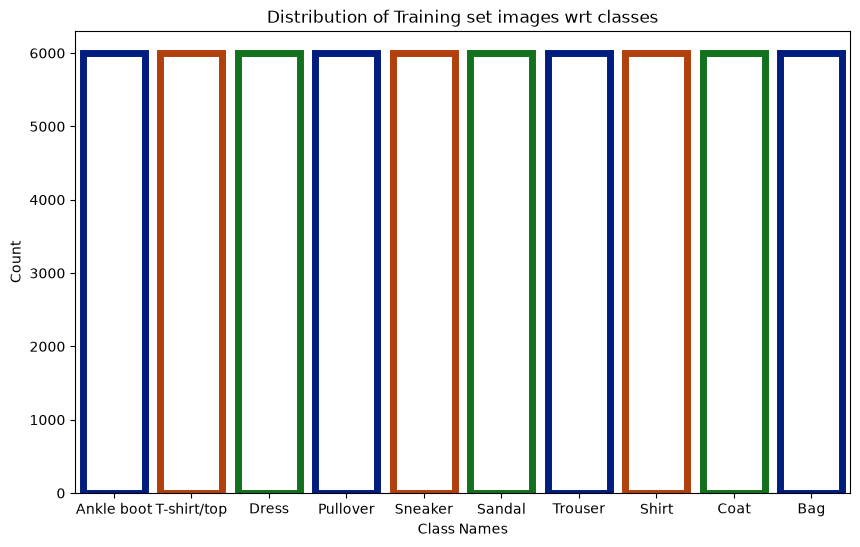

In [56]:
train_df['label_names'] = train_df['label'].map(classes)

# NOTE: seaborn 0.13.x `countplot` mis-counts categoricals under pandas 3.0's
# new string dtype (a library bug, not a data problem). We aggregate first and
# draw the same chart with `barplot`.
counts = train_df['label_names'].value_counts().reset_index()
counts.columns = ['class', 'count']

plt.figure(figsize=(10,6))
sns.barplot(x='class', y='count', data=counts, facecolor=(0, 0, 0, 0),
            linewidth=5, edgecolor=sns.color_palette("dark", 3))
plt.xlabel('Class Names')
plt.ylabel('Count')
plt.title('Distribution of Training set images wrt classes')
plt.show()

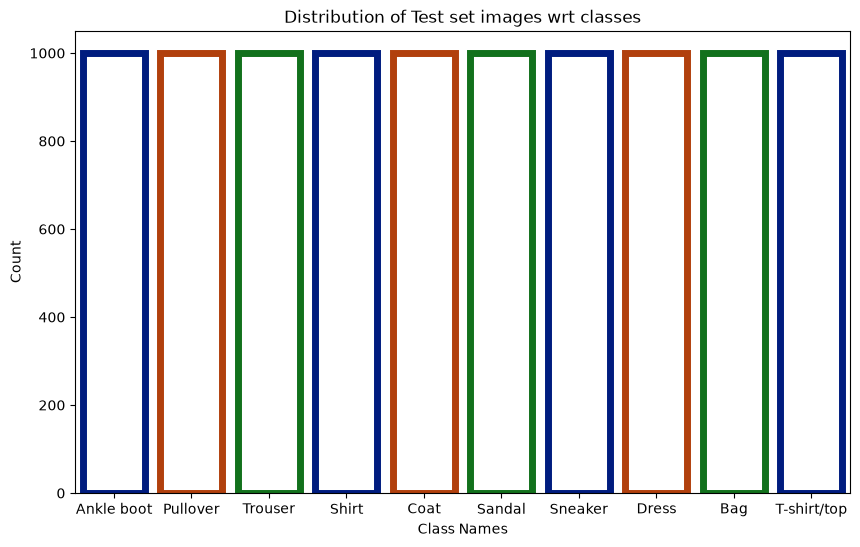

In [57]:
test_df['label_names'] = test_df['label'].map(classes)

counts = test_df['label_names'].value_counts().reset_index()
counts.columns = ['class', 'count']

plt.figure(figsize=(10,6))
sns.barplot(x='class', y='count', data=counts, facecolor=(0, 0, 0, 0),
            linewidth=5, edgecolor=sns.color_palette("dark", 3))
plt.xlabel('Class Names')
plt.ylabel('Count')
plt.title('Distribution of Test set images wrt classes')
plt.show()

**Let's see the shape of training and test set.**

In [8]:
train_df.shape

(60000, 786)

In [9]:
test_df.shape

(10000, 786)

<a id="section-pre"></a>
**Let's prepare our data for preprocessing. First, we're going to divide training and test sets into features and labels.**

In [10]:
# Drop the helper label_names column; keep raw integer labels (no one-hot!)
X_train = train_df.drop(columns=['label', 'label_names'])
y_train = train_df['label']

X_test = test_df.drop(columns=['label', 'label_names'])
y_test = test_df['label']

**Now we're going to reshape our images**

The CSV stores each image as 784 flat pixels; we reshape them back to 28x28.

In [11]:
X_train = X_train.values.reshape(X_train.shape[0], 28, 28)
X_test  = X_test.values.reshape(X_test.shape[0], 28, 28)

**Let's check the shapes again**

In [12]:
X_train.shape

(60000, 28, 28)

In [13]:
X_test.shape

(10000, 28, 28)

*Let's visualize a single image from our training set*

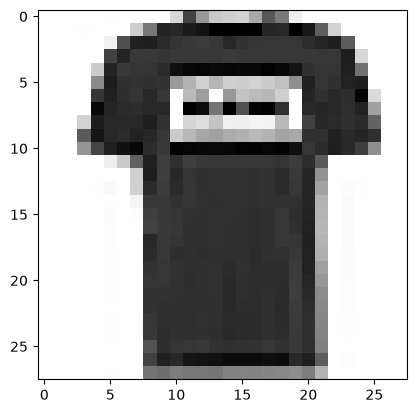

In [14]:
single_image = X_train[1]
plt.imshow(single_image, cmap='binary')
plt.show()

*This looks like an ankle boot to me. Let's check the labels to confirm it*

In [15]:
y_train

0        9
1        0
2        0
3        3
4        0
        ..
59995    5
59996    1
59997    3
59998    0
59999    5
Name: label, Length: 60000, dtype: int64

Index **1** has **9** as a value which is the **key of Ankle boot** as per the **classes dictionary**, so we stand correct.

**Labels: no `to_categorical` in PyTorch.** Keras' `categorical_crossentropy`
needs one-hot targets, so the original notebook called `to_categorical`.
PyTorch's `nn.CrossEntropyLoss` expects **integer** class indices and applies the
softmax internally — so we leave `y_train`/`y_test` as plain integer labels.

Now we're going to normalize our images. Right now the pixel values range from
**0** to **255**. We convert them to the **0 to 1** range (the same `/255`
approach the original notebook used).

In [16]:
X_train = X_train / 255.
X_test  = X_test / 255.

print('min/max after scaling:', X_train.min(), X_train.max())

min/max after scaling: 0.0 1.0


*Let's visualize that **Ankle boot** image in the form of pixels*

In [17]:
def plot_digit(digit, dem = 28, font_size = 12):
    max_ax = font_size * dem

    fig = plt.figure(figsize=(13, 13))
    plt.xlim([0, max_ax])
    plt.ylim([0, max_ax])
    plt.axis('off')
    black = '#000000'

    for idx in range(dem):
        for jdx in range(dem):
            t = plt.text(idx * font_size, max_ax - jdx*font_size, digit[jdx][idx], fontsize = font_size, color = black)
            c = digit[jdx][idx] / 255.
            t.set_bbox(dict(facecolor=(c, c, c), alpha = 0.5, edgecolor = 'black'))

    plt.show()

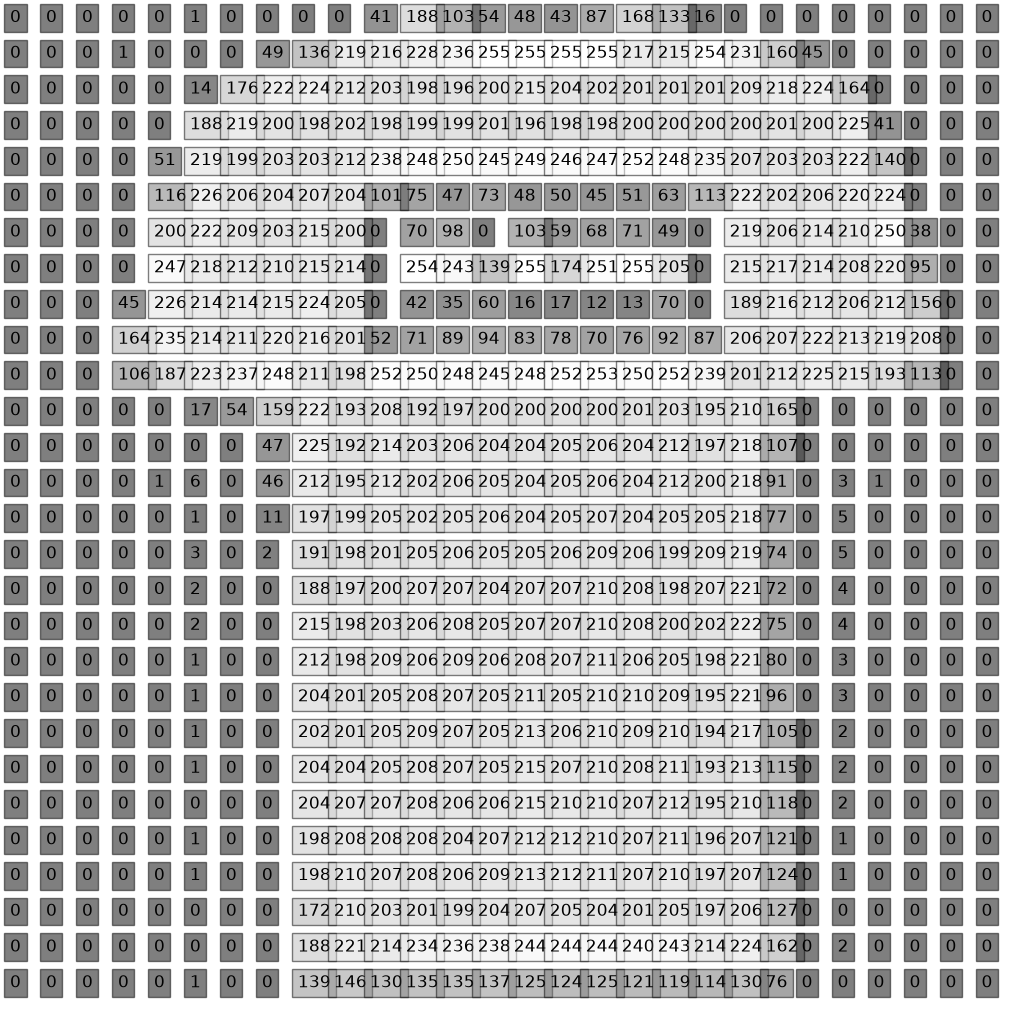

In [18]:
plot_digit((X_train[1] * 255).astype(int))

**Adding the channel dimension — and the NCHW vs NHWC flip.**

Keras expects channels **last**: `(N, 28, 28, 1)`. PyTorch expects channels
**first**: `(N, 1, 28, 28)`. We use `.unsqueeze(1)` to insert the single
grayscale channel at position 1. We also convert everything to `torch.Tensor`s
here (labels use `torch.long` because `CrossEntropyLoss` needs integer targets).

In [19]:
# numpy (N, 28, 28) -> torch (N, 1, 28, 28), i.e. NCHW
X_train = torch.tensor(X_train, dtype=torch.float32).unsqueeze(1)
X_test  = torch.tensor(X_test,  dtype=torch.float32).unsqueeze(1)
y_train = torch.tensor(y_train.to_numpy(), dtype=torch.long)
y_test  = torch.tensor(y_test.to_numpy(),  dtype=torch.long)

# Keep a numpy copy of the images for plotting later
X_test_np = X_test.squeeze(1).cpu().numpy()

print('X_train:', tuple(X_train.shape))   # (60000, 1, 28, 28)
print('X_test :', tuple(X_test.shape))    # (10000, 1, 28, 28)
print('y_train:', tuple(y_train.shape))

X_train: (60000, 1, 28, 28)
X_test : (10000, 1, 28, 28)
y_train: (60000,)


<a id="section-nn"></a>
*Now we're done with our image preprocessing step, let's divide our data into
training and validation set. We're gonna set validation set size to 20%.*

In Keras, batching happens inside `model.fit(batch_size=128)`. In PyTorch we
wrap the tensors in `TensorDataset` and let a `DataLoader` handle batching and
shuffling.

In [20]:
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=0.2, random_state=42
)

BATCH_SIZE = 128
train_loader = DataLoader(TensorDataset(X_tr, y_tr), batch_size=BATCH_SIZE, shuffle=True)
val_loader   = DataLoader(TensorDataset(X_val, y_val), batch_size=BATCH_SIZE, shuffle=False)
test_loader  = DataLoader(TensorDataset(X_test, y_test), batch_size=256, shuffle=False)

print(f'train {len(X_tr)} | val {len(X_val)} | test {len(X_test)}')

train 48000 | val 12000 | test 10000


**Now let's structure our Convolutional Neural Network model which we will train**

Keras' `Sequential` is replaced by a subclass of `nn.Module`. Two important
differences from the original:

1. `nn.Conv2d(in_channels, out_channels, ...)` — the first argument is the
   number of **input channels** (1 for grayscale), the second the filters.
2. **No `softmax` on the last layer.** `nn.CrossEntropyLoss` applies
   `log_softmax` internally, so the network outputs **raw logits**.
3. **The flatten size must be computed by hand** (Keras infers it). After three
   2x2 max-pools the 28x28 maps become 14x14 -> 7x7 -> 3x3, so we feed
   `128 * 3 * 3` into the first `Linear`.

In [21]:
class FashionCNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            # --- Block 1 ---
            nn.Conv2d(1, 32, kernel_size=4, padding='same'),
            nn.ReLU(),
            nn.BatchNorm2d(32),
            nn.MaxPool2d(2),

            # --- Block 2 ---
            nn.Conv2d(32, 64, kernel_size=4, padding='same'),
            nn.ReLU(),
            nn.BatchNorm2d(64),
            nn.MaxPool2d(2),
            nn.Dropout(0.3),
            nn.BatchNorm2d(64),

            # --- Block 3 ---
            nn.Conv2d(64, 128, kernel_size=4, padding='same'),
            nn.ReLU(),
            nn.Conv2d(128, 128, kernel_size=4, padding='same'),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.BatchNorm2d(128),
            nn.MaxPool2d(2),
            nn.BatchNorm2d(128),
            nn.Dropout(0.3),

            # --- Classifier head ---
            nn.Flatten(),
            nn.Linear(128 * 3 * 3, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, num_classes),   # raw logits — no softmax!
        )

    def forward(self, x):
        return self.features(x)


model = FashionCNN().to(device)

In [22]:
# Verify the flattened size assumption with a dummy forward pass
with torch.no_grad():
    dummy = model(torch.randn(1, 1, 28, 28).to(device))
print('output shape:', tuple(dummy.shape))   # -> (1, 10)

output shape: (1, 10)


/home/akhil/Documents/code/github.com/akhilmk/ann-workbook/fashion-mnist/.venv/lib/python3.12/site-packages/torch/nn/modules/conv.py:560: UserWarning: Using padding='same' with even kernel lengths and odd dilation may require a zero-padded copy of the input be created (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/native/Convolution.cpp:1104.)
  return F.conv2d(


`model.summary()` in Keras maps to `torchinfo` (or simply `print(model)`).

In [23]:
try:
    from torchinfo import summary
    summary(model, input_size=(1, 1, 28, 28))
except ImportError:
    print(model)

**filters:-** how many filters to apply on an image

**kernel_size:-** size of the matrix which strides through the whole image

**padding:-** extra padding at the corners ("same" keeps the spatial size).

**Flatten:-** flattens the 3D feature maps into a vector before the dense layers.

**Batch Normalization / Dropout** are regularisation layers. Remember: in
PyTorch they behave differently in training vs. evaluation — `model.train()` and
`model.eval()` switch them. Forgetting this is a classic PyTorch bug.

**Loss & optimizer.** `categorical_crossentropy` -> `nn.CrossEntropyLoss`
(fused softmax + NLL, expects logits + integer labels). `Adam(lr=...)` ->
`optim.Adam(model.parameters(), lr=...)`.

In [24]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001, betas=(0.9, 0.999))

*Using **Early Stopping to monitor the validation loss** and **stop the training
when the loss begins to increase**. **Patience** lets us set the number of epochs
after which the training should be stopped in case of validation loss. We're
setting it at 18.*

Keras gives this as a callback; in PyTorch we write a tiny class and call it once
per epoch inside the manual training loop.

In [25]:
class EarlyStopping:
    """Stops training when val_loss doesn't improve for `patience` epochs."""
    def __init__(self, patience=18, min_delta=0.0):
        self.patience = patience
        self.min_delta = min_delta
        self.counter = 0
        self.best_loss = None
        self.early_stop = False

    def __call__(self, val_loss):
        if self.best_loss is None or val_loss < self.best_loss - self.min_delta:
            self.best_loss = val_loss
            self.counter = 0
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.early_stop = True
        return self.early_stop

**The training loop.** This is what `model.fit(...)` did for us in Keras. The
canonical order per batch is:

`optimizer.zero_grad()` -> `forward` -> `loss` -> `loss.backward()` -> `optimizer.step()`.

In [26]:
def train_one_epoch(model, loader, criterion, optimizer, device):
    model.train()                       # enable dropout + batchnorm training behaviour
    running_loss, correct, total = 0.0, 0, 0
    for X_batch, y_batch in loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)

        optimizer.zero_grad()           # clear gradients from the previous step
        outputs = model(X_batch)        # forward pass -> raw logits
        loss = criterion(outputs, y_batch)
        loss.backward()                 # backpropagation
        optimizer.step()                # update weights

        running_loss += loss.item() * X_batch.size(0)
        correct += (outputs.argmax(1) == y_batch).sum().item()
        total += y_batch.size(0)
    return running_loss / total, correct / total


@torch.no_grad()
def evaluate(model, loader, criterion, device):
    model.eval()                        # disable dropout + freeze batchnorm stats
    running_loss, correct, total = 0.0, 0, 0
    for X_batch, y_batch in loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        outputs = model(X_batch)
        loss = criterion(outputs, y_batch)

        running_loss += loss.item() * X_batch.size(0)
        correct += (outputs.argmax(1) == y_batch).sum().item()
        total += y_batch.size(0)
    return running_loss / total, correct / total

In [27]:
EPOCHS = 100
early_stop = EarlyStopping(patience=18)

history = {'loss': [], 'val_loss': [], 'accuracy': [], 'val_accuracy': []}

for epoch in range(1, EPOCHS + 1):
    train_loss, train_acc = train_one_epoch(model, train_loader, criterion, optimizer, device)
    val_loss, val_acc = evaluate(model, val_loader, criterion, device)

    history['loss'].append(train_loss)
    history['accuracy'].append(train_acc)
    history['val_loss'].append(val_loss)
    history['val_accuracy'].append(val_acc)

    print(f'Epoch {epoch:03d} | loss {train_loss:.4f} | acc {train_acc:.4f} | '
          f'val_loss {val_loss:.4f} | val_acc {val_acc:.4f}')

    if early_stop(val_loss):
        print(f'Early stopping at epoch {epoch}')
        break

Epoch 001 | loss 0.4585 | acc 0.8332 | val_loss 0.3369 | val_acc 0.8798
Epoch 002 | loss 0.3011 | acc 0.8894 | val_loss 0.3040 | val_acc 0.8974
Epoch 003 | loss 0.2664 | acc 0.9028 | val_loss 0.3186 | val_acc 0.9115
Epoch 004 | loss 0.2435 | acc 0.9094 | val_loss 0.2765 | val_acc 0.9085
Epoch 005 | loss 0.2275 | acc 0.9150 | val_loss 0.2591 | val_acc 0.9038
Epoch 006 | loss 0.2124 | acc 0.9216 | val_loss 0.2156 | val_acc 0.9198
Epoch 007 | loss 0.1974 | acc 0.9273 | val_loss 0.2198 | val_acc 0.9187
Epoch 008 | loss 0.1865 | acc 0.9329 | val_loss 0.2730 | val_acc 0.9188
Epoch 009 | loss 0.1802 | acc 0.9334 | val_loss 0.3369 | val_acc 0.9180
Epoch 010 | loss 0.1711 | acc 0.9356 | val_loss 0.2293 | val_acc 0.9193
Epoch 011 | loss 0.1627 | acc 0.9389 | val_loss 0.2307 | val_acc 0.9235
Epoch 012 | loss 0.1603 | acc 0.9412 | val_loss 0.1995 | val_acc 0.9267
Epoch 013 | loss 0.1451 | acc 0.9458 | val_loss 0.2157 | val_acc 0.9246
Epoch 014 | loss 0.1410 | acc 0.9474 | val_loss 0.3105 | val_acc

Save the trained weights (a new capability PyTorch makes explicit):

In [ ]:
CKPT = ROOT / 'fashion_cnn.pth'
torch.save(model.state_dict(), CKPT)
print('saved ->', CKPT)

In [29]:
metrics = pd.DataFrame(history)
metrics.head()

,loss,val_loss,accuracy,val_accuracy
0,0.458512,0.336931,0.833229,0.879750
1,0.301067,0.303966,0.889354,0.897417
2,0.266427,0.318640,0.902813,0.911500
3,0.243542,0.276499,0.909396,0.908500
4,0.227522,0.259095,0.915021,0.903750


<a id="section-acc"></a>
*Plotting the loss and accuracy metrics*

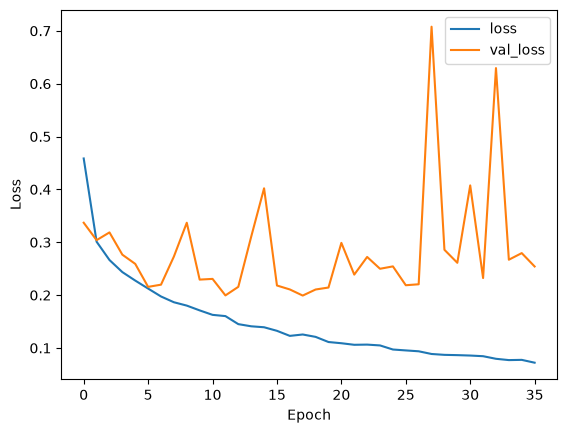

In [30]:
metrics[['loss', 'val_loss']].plot()
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.show()

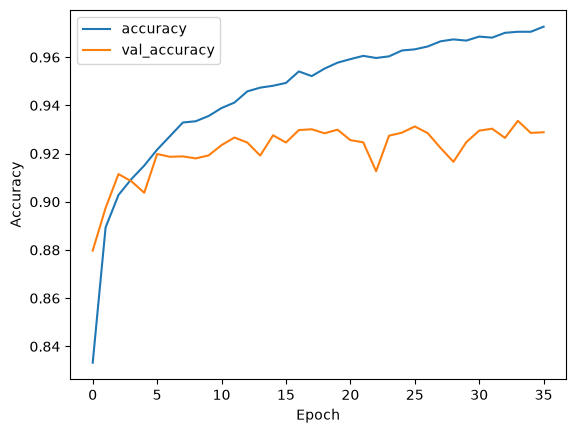

In [31]:
metrics[['accuracy', 'val_accuracy']].plot()
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.show()

**Evaluating the model on the test set**

Keras' `model.evaluate(...)` returns `[loss, accuracy]`; our `evaluate()` helper
does the same.

In [32]:
test_loss, test_acc = evaluate(model, test_loader, criterion, device)
print(f'Test loss: {test_loss:.4f} | Test accuracy: {test_acc:.4f}')

Test loss: 0.3250 | Test accuracy: 0.9259


*The Keras notebook reached ~93.2% test accuracy. As noted there, the
`val_loss` started rising a little, so extra regularisation / a smaller patience
would help.*

<a id="section-true"></a>
**Let's visualize the true and predicted classes**

`model.predict(X_test)` becomes a small `@torch.no_grad()` helper that
concatenates batched logits.

In [33]:
@torch.no_grad()
def predict(model, loader, device):
    model.eval()
    preds = []
    for X_batch, _ in loader:
        outputs = model(X_batch.to(device))
        preds.append(outputs.cpu())        # numpy can't read CUDA tensors
    return torch.cat(preds)

predictions = predict(model, test_loader, device)   # raw logits, shape (N, 10)

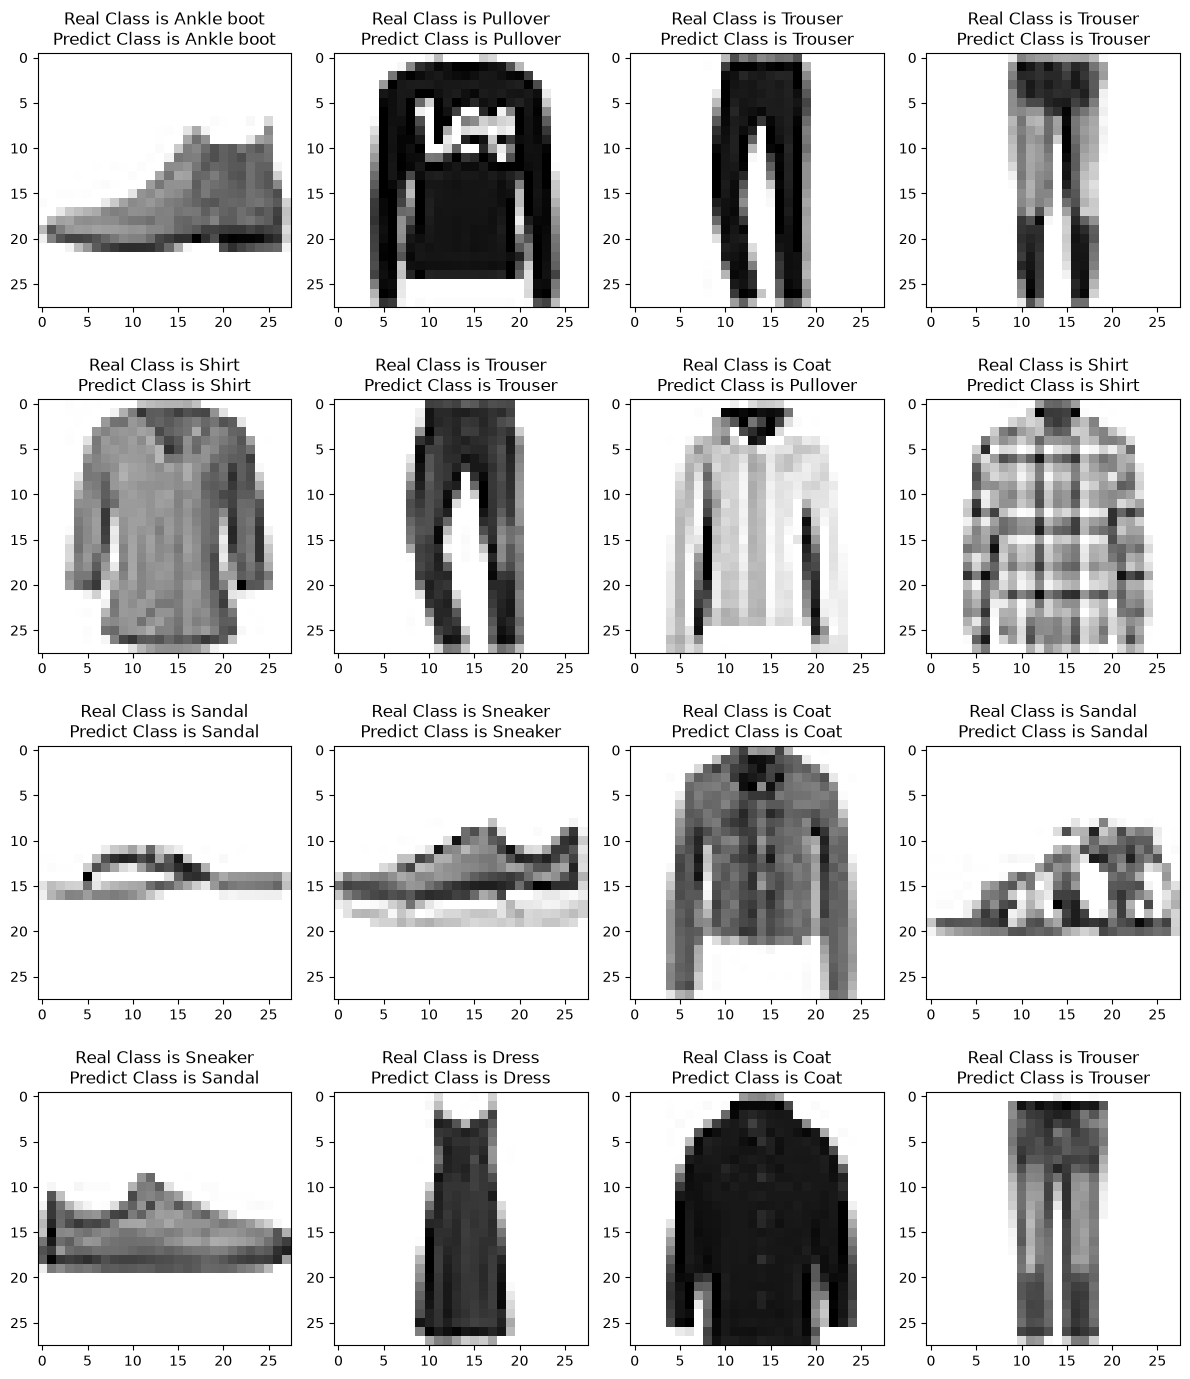

In [34]:
fig, axis = plt.subplots(4, 4, figsize=(12, 14))
for i, ax in enumerate(axis.flat):
    ax.imshow(X_test_np[i], cmap='binary')
    real = classes[y_test[i].item()]
    pred = classes[predictions[i].argmax().item()]
    ax.set(title = f"Real Class is {real}\nPredict Class is {pred}")
plt.tight_layout()
plt.show()

<a id="section-class"></a>
***Let's create Confusion Matrix and Classification report to get a summary of how accurate our model was***

Note: `y_test` is already an integer label tensor in PyTorch, so we no longer need
`np.argmax(y_cat_test, axis=1)` for the true labels.

In [35]:
predictions_classes = predictions.argmax(dim=1).numpy()
y_true = y_test.numpy()

print(classification_report(y_true, predictions_classes))

              precision    recall  f1-score   support

           0       0.89      0.86      0.87      1000
           1       0.99      0.99      0.99      1000
           2       0.89      0.88      0.89      1000
           3       0.92      0.93      0.93      1000
           4       0.86      0.91      0.89      1000
           5       0.99      0.99      0.99      1000
           6       0.79      0.77      0.78      1000
           7       0.96      0.98      0.97      1000
           8       0.99      0.98      0.99      1000
           9       0.98      0.96      0.97      1000

    accuracy                           0.93     10000
   macro avg       0.93      0.93      0.93     10000
weighted avg       0.93      0.93      0.93     10000



**Precision:-** the number of positive class predictions that actually belong to the positive class.

**Recall:-** the number of positive class predictions made out of all positive examples in the dataset.

**F1-score:-** a single score that balances both precision and recall.

In [36]:
print(confusion_matrix(y_true, predictions_classes))

[[858   1  14  15   5   0 104   0   3   0]
 [  0 986   0  10   1   0   2   0   1   0]
 [ 16   1 882   7  56   0  38   0   0   0]
 [ 11   6   6 934  21   0  21   0   0   1]
 [  0   0  27  20 911   0  42   0   0   0]
 [  0   0   0   0   0 990   0   5   0   5]
 [ 78   2  56  25  62   0 773   0   4   0]
 [  0   0   0   0   0   7   0 982   0  11]
 [  3   1   1   6   2   1   4   1 981   0]
 [  0   0   1   0   0   4   0  33   0 962]]


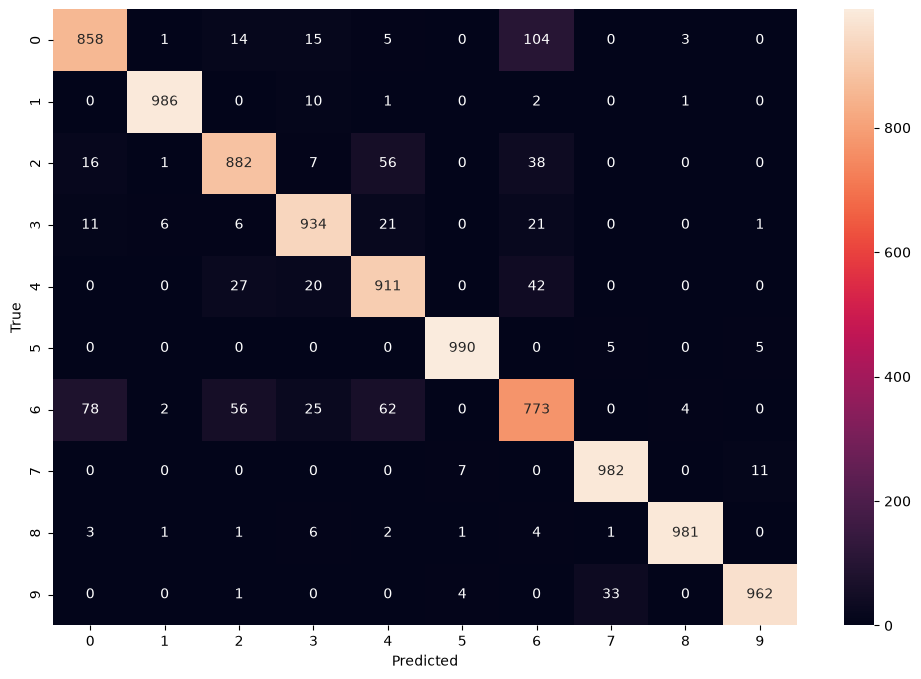

In [37]:
plt.figure(figsize = (12, 8))
sns.heatmap(confusion_matrix(y_true, predictions_classes), annot=True, fmt='d')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()

**Confusion Matrix:-** a tabular summary of the number of correct and incorrect
predictions made by a classifier.

### Reloading a saved model

Because we saved only the `state_dict`, we must recreate the architecture first.

In [ ]:
loaded = FashionCNN().to(device)
loaded.load_state_dict(torch.load(CKPT, map_location=device))
loaded.eval()
_, reloaded_acc = evaluate(loaded, test_loader, criterion, device)
print(f'Reloaded model test accuracy: {reloaded_acc:.4f}')

**References:-**
* Original TensorFlow/Keras notebook: `fashion-cnn-tf.ipynb`
* dataset from [https://www.kaggle.com/zalando-research/fashionmnist](http://)
* Migration cheat-sheet & notes: `MIGRATION-TO-PYTORCH.md`